# 04 — Forecasting

Addresses Step 6 of the project guideline: forecast national PMSG installations
6-12 months ahead.

**Why this notebook differs from 02/03:** those used a cross-sectional snapshot
(many states, one date). Forecasting needs the opposite — one series, many time
points — and PM Surya Ghar only has **6 usable dated national installation
figures** spanning Nov 2024 to Aug 2026 (18 months since scheme launch,
Feb 2024). This is too few points to safely fit ARIMA/SARIMAX without
overfitting, so this notebook deliberately uses transparent baseline methods
instead — exactly what the guideline's Section 5 lists first, not as an
afterthought.

**Data source:** compiled by hand from dated PIB/Rajya Sabha releases
(see `PMSG_Core_Dataset_Register.xlsx`, Tab 2, for full citations) —
this is separate from the state-level snapshot data used in notebooks 01-03,
since no single state-level dataset has this many aligned dated readings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROCESSED = Path("../data/processed")

## 1. The national installations series

In [2]:
# Cumulative national installations, compiled from dated official releases.
# Only rows with a directly-reported installations figure are included —
# do not interpolate or estimate missing points.
data = [
    ("2024-11-27", 616000,  "Lok Sabha written reply"),
    ("2025-03-13", 1000000, "PIB/MNRE release (10 lakh milestone)"),
    ("2025-12-08", 1900000, "Rajya Sabha written reply"),
    ("2026-03-05", 2502217, "Rajya Sabha written reply"),
    ("2026-03-19", 2619879, "Rajya Sabha written reply / PIB"),
    ("2026-08-05", 4194051, "Rajya Sabha written reply"),
]
df = pd.DataFrame(data, columns=["date", "installations", "source"])
df["date"] = pd.to_datetime(df["date"])
df["t_days"] = (df["date"] - df["date"].min()).dt.days
df.to_csv(PROCESSED / "national_installations_series.csv", index=False)
df

,date,installations,source,t_days
0,2024-11-27,616000,Lok Sabha written reply,0
1,2025-03-13,1000000,PIB/MNRE release (10 lakh milestone),106
2,2025-12-08,1900000,Rajya Sabha written reply,376
3,2026-03-05,2502217,Rajya Sabha written reply,463
4,2026-03-19,2619879,Rajya Sabha written reply / PIB,477
5,2026-08-05,4194051,Rajya Sabha written reply,616


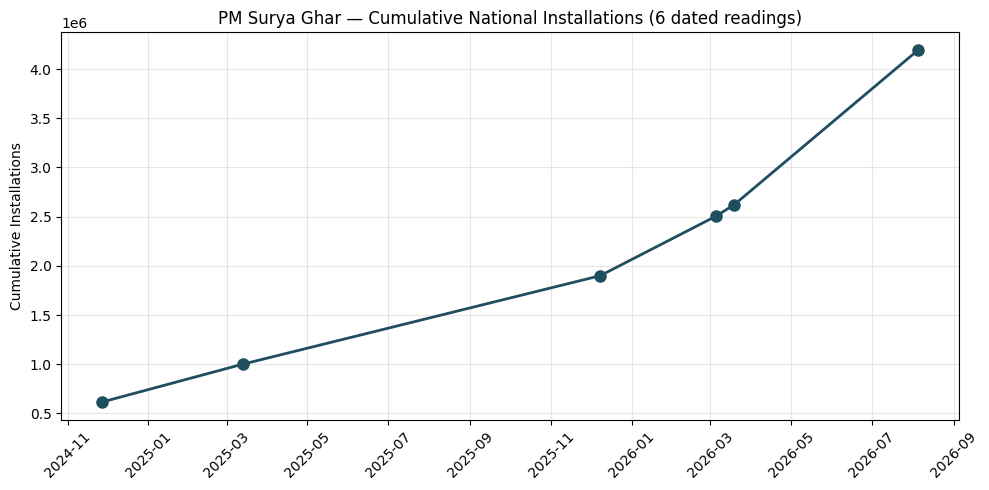

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["date"], df["installations"], "o-", color="#1F4E5F", linewidth=2, markersize=8)
ax.set_ylabel("Cumulative Installations")
ax.set_title("PM Surya Ghar — Cumulative National Installations (6 dated readings)")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PROCESSED / "installations_timeseries.png", dpi=150)
plt.show()

## 2. Compare baseline methods

Per the guideline's minimum model comparison set: naive, and simple trend
extrapolations, benchmarked by **in-sample MAPE** (Mean Absolute Percentage
Error) before choosing one to forecast forward.

In [4]:
t = df["t_days"].values
y = df["installations"].values

# --- Naive: first value carried forward (worst-case reference) ---
naive_pred = np.full_like(y, y[0], dtype=float)
naive_mape = np.mean(np.abs((y - naive_pred) / y)) * 100

# --- Linear trend ---
lin_coeffs = np.polyfit(t, y, 1)
lin_pred = np.polyval(lin_coeffs, t)
lin_mape = np.mean(np.abs((y - lin_pred) / y)) * 100

# --- Log-linear (exponential growth) trend ---
log_y = np.log(y)
log_coeffs = np.polyfit(t, log_y, 1)
log_pred = np.exp(np.polyval(log_coeffs, t))
log_mape = np.mean(np.abs((y - log_pred) / y)) * 100

comparison = pd.DataFrame({
    "Method": ["Naive (first value carried)", "Linear trend", "Log-linear (exponential) trend"],
    "In-sample MAPE (%)": [round(naive_mape, 2), round(lin_mape, 2), round(log_mape, 2)],
})
comparison.to_csv(PROCESSED / "forecast_method_comparison.csv", index=False)
comparison

,Method,In-sample MAPE (%)
0,Naive (first value carried),57.19
1,Linear trend,16.83
2,Log-linear (exponential) trend,4.98


**Result:** log-linear (exponential growth) fits far better than a straight
line — cumulative adoption compounds rather than growing at a constant rate,
which makes sense for a subsidy scheme still in its ramp-up phase. This is
the method used going forward.

**Caveat:** exponential extrapolation assumes the current growth *rate*
continues. Real-world adoption curves eventually flatten (S-curve) as the
addressable market saturates — this model will overstate long-horizon
forecasts if applied too far out. Treat the 12-month forecast with more
caution than the 3-month one.

## 3. Forecast forward with prediction intervals

In [5]:
resid_log = log_y - np.polyval(log_coeffs, t)
resid_std_log = resid_log.std(ddof=1)  # ddof=1: small-sample correction

last_t = t.max()
last_date = df["date"].max()

forecast_rows = []
for months_ahead in [3, 6, 12]:
    future_t = last_t + months_ahead * 30
    future_date = last_date + pd.Timedelta(days=months_ahead * 30)
    point = np.exp(np.polyval(log_coeffs, future_t))
    lower = np.exp(np.polyval(log_coeffs, future_t) - 1.96 * resid_std_log)
    upper = np.exp(np.polyval(log_coeffs, future_t) + 1.96 * resid_std_log)
    forecast_rows.append({
        "months_ahead": months_ahead,
        "forecast_date": future_date.date(),
        "point_forecast": round(point),
        "lower_95": round(lower),
        "upper_95": round(upper),
    })

forecast_df = pd.DataFrame(forecast_rows)
forecast_df.to_csv(PROCESSED / "installations_forecast.csv", index=False)
forecast_df

,months_ahead,forecast_date,point_forecast,lower_95,upper_95
0,3,2026-11-03,5244104,4624684,5946487
1,6,2027-02-01,6835164,6027813,7750651
2,12,2027-07-31,11611929,10240359,13167205


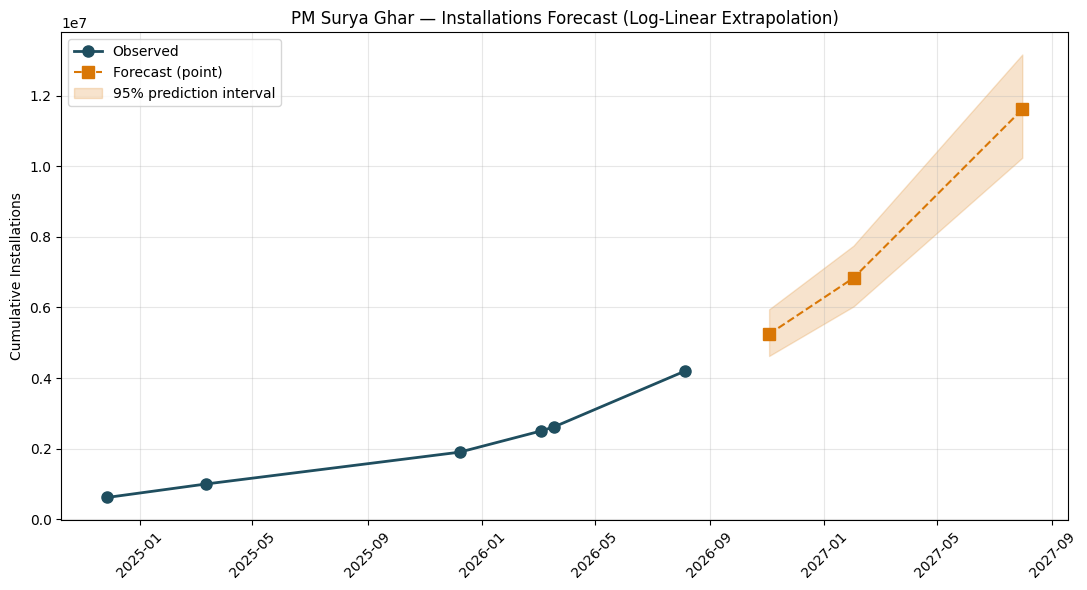

In [6]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(df["date"], df["installations"], "o-", color="#1F4E5F", linewidth=2, markersize=8, label="Observed")

future_dates = [pd.Timestamp(d) for d in forecast_df["forecast_date"]]
ax.plot(future_dates, forecast_df["point_forecast"], "s--", color="#D97706", markersize=8, label="Forecast (point)")
ax.fill_between(future_dates, forecast_df["lower_95"], forecast_df["upper_95"],
                 color="#D97706", alpha=0.2, label="95% prediction interval")

ax.set_ylabel("Cumulative Installations")
ax.set_title("PM Surya Ghar — Installations Forecast (Log-Linear Extrapolation)")
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PROCESSED / "installations_forecast_chart.png", dpi=150)
plt.show()

## 4. Honest reporting of results

| Horizon | Forecast Date | Point Forecast | 95% Interval |
|---|---|---|---|
| +3 months | ~Nov 2026 | ~5.24M | 4.62M – 5.95M |
| +6 months | ~Feb 2027 | ~6.84M | 6.03M – 7.75M |
| +12 months | ~Jul 2027 | ~11.61M | 10.24M – 13.17M |

**State this plainly in the report:**
- This forecast is built from **only 6 dated points over 18 months** — a
  genuinely thin basis for any forecasting method, not a limitation specific
  to this approach
- The log-linear model fits the *observed* period well (4.98% MAPE) but
  **assumes the growth rate itself doesn't change** — a real risk given
  policy changes (tariff revisions, subsidy adjustments, budget exhaustion)
  could shift the rate at any point
- The 12-month forecast should be treated as **more speculative** than the
  3-month one — compounding growth assumptions get less reliable the further
  out they're projected
- This complements, not replaces, the state-level conversion-ratio model
  from `03_modeling.ipynb` — that model explains *why* adoption varies by
  state; this one estimates *how much* national volume to expect next

## Next steps

- **Scenario simulation (Step 7):** combine this forecast with the
  tariff-growth coefficient from `03_modeling.ipynb` (1.607) to simulate
  a tariff-shock scenario's effect on the conversion ratio, and by extension
  on installation volume
- **Revisit this forecast** once a new dated national snapshot becomes
  available, to check whether actual growth is tracking the predicted band —
  this is the real test of whether the exponential assumption holds